# Solar System Visibility Checker
A companion to `target_visibility.ipynb` for planets and their major moons, whose positions come from [JPL Horizons](https://ssd.jpl.nasa.gov/horizons/) instead of a fixed sky coordinate.

- **Cell 1**: imports. The helper functions live in `helpers.py` and `solar_system_helpers.py` beside this notebook.
- **Cell 2**: everything you edit: `targets_list`, the UTC start/stop, the cadence, the TLE and the `Visibility` settings.
- **Cell 3**: ephemerides of every body in each target's system from Horizons, with how often each moon is free and clear.
- **Cell 4**: visibility per target, one best-roll search per day.
- **Cell 5**: the pointing RA and Dec over time, and how far each body of the system is from the target.
- **Cell 6**: one timeline per target: when it is visible, and when each body of its system is free and clear.
- **Cell 7**: which pointing constraint is failing while the target is not visible.
- **Cell 8**: the simulated NIRDA subarray each day, at the roll held that day.

A target can be a planet (`"Saturn"`) or a major moon (`"Titan"`); see `PLANETS` and `MAJOR_MOONS` in `solar_system_helpers.py` for the names known. Each target is put at the NIRDA pivot in turn, and the rest of its system (the planet and its major moons) is drawn around it.

Horizons is queried over the internet once per body. Its positions are geocentric: Pandora's ~7,000 km offset from the Earth's center moves every body of a planetary system by the same ~1 arcsec, so the geometry between them, which decides occultations and trace overlaps, is unchanged. The NIRDA panels also use the offline Gaia DR3 catalog from `gaiaoffline` for field stars; set `include_field_stars = False` in Cell 2 to run without it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.coordinates import SkyCoord
from matplotlib.patches import Patch

from helpers import (
    build_time_grid,
    draw_event_box,
    draw_row,
    format_date_axis,
    label_rows,
    mask_segments,
    run_stats,
)
from solar_system_helpers import (
    VISIBILITY_CODES,
    is_clear,
    mean_coord,
    pandora_centric,
    resolve_body,
    system_ephemerides,
    system_field,
    system_ids,
)
from pandoravisibility import Visibility, trace, version

print(f"Pandora Visibility Version: {version}.")

Pandora Visibility Version: 2.1.0.


## Edit this cell

`targets_list` takes planet and major moon names, mixed freely. The keep-outs are the same settings as `target_visibility.ipynb`. The NIRDA trace check of the roll search is switched off here: it needs the target to be a Gaia star, which planets and moons are not, so it would only skip them with a warning. Cell 8 draws the system's traces instead.

In [2]:
# Targets: planets or major moons, by name
targets_list = ["Saturn", "Titan", "Enceladus"]

# Time window (UTC) and cadence. Each day of the window gets its own roll.
start_utc = "2026-10-26T00:00:00"
stop_utc = "2026-10-28T00:00:00"
time_step_minutes = 1.0

# Spacecraft orbit
# Placeholder TLE for Pandora (epoch 2026-10-21); use the newest one for real work!
line1 = "1 67395U 80229J   26294.59710648  .00000000  00000-0 -27326-5 0    03"
line2 = "2 67395  97.8123 291.3619 0006725  75.0159  26.3840 14.88223568    00"

# The class defaults as of v2.1.0, spelled out so the run stays pinned if the
# defaults move again. Change any of them here, e.g. st_required=2.
visibility_settings = dict(
    earthlimb_day_min=44 * u.deg,
    earthlimb_night_min=13 * u.deg,
    sun_min=91 * u.deg,
    moon_min=20 * u.deg,
    st_sun_min=50 * u.deg,
    st_moon_min=20 * u.deg,
    st_earthlimb_min=30 * u.deg,
    st_required=1,
    use_dynamic_earthlimb=True,
    # Sun/Moon evaluated hourly and interpolated; directions stay good to well
    # under 0.01 deg. Drop this line to evaluate the ephemeris exactly.
    ephemeris_step=60 * u.min,
    # Off: the roll search's trace check needs a Gaia star at the target.
    use_trace_sweep=False,
    # NIRDA subarray drawn in Cell 8
    nirda_roi_x=80,
    nirda_roi_y=256,
)
visibility = Visibility(line1, line2, **visibility_settings)

# Roll sweep resolution for the optimize_roll search
roll_step = 1 * u.deg

# Gaia field stars in the Cell 8 panels (needs the gaiaoffline database)
include_field_stars = True

times = build_time_grid(start_utc, stop_utc, time_step_minutes)

print(visibility)
print(f"Orbital period: {visibility.get_period():.2f}")
print(f"{len(times)} steps of {time_step_minutes:g} min: "
      f"{times[0].iso} → {times[-1].iso}")

<Visibility: SAT67395 [moon≥20 deg, sun≥91 deg, limb=dynamic, st_sun≥50 deg, st_moon≥20 deg, st_limb≥30 deg, st_req=1]>
Orbital period: 96.76 min
2880 steps of 1 min: 2026-10-26 00:00:00.000 → 2026-10-27 23:59:00.000


## Ephemerides from JPL Horizons

One Horizons table per body, on the same time grid: astrometric position, visual magnitude, angular diameter, ring opening angle and pole position angle, and for moons a visibility code relative to their planet. Only **free and clear** (`*`) counts as observable; Horizons' other codes mean the moon is transiting the planet's disk, occulted by it, or in its shadow (eclipsed). Horizons treats the planet as a sphere of its equatorial radius and ignores rings, so a moon grazing the limb or behind the rings may be classed slightly wrong.

In [3]:
targets = [resolve_body(name) for name in targets_list]
target_ids = [target_id for target_id, _ in targets]
labels = {
    body_id: resolve_body(body_id)[1]
    for target_id in target_ids
    for body_id in system_ids(target_id)
}
ephemerides = system_ephemerides(
    target_ids, start_utc, stop_utc, time_step_minutes, times
)

shown_systems = []
for target_id in target_ids:
    system = system_ids(target_id)
    if system[0] in shown_systems:
        continue
    shown_systems.append(system[0])
    print(f"\n{labels[system[0]]} system")
    print(f"  {'Body':<11}{'V':>7}{'diameter':>10}{'clear':>8}  other states")
    for body_id in system:
        ephemeris = ephemerides[body_id]
        clear = is_clear(body_id, ephemeris)
        states = []
        if body_id % 100 != 99:
            codes, counts = np.unique(ephemeris["code"][~clear], return_counts=True)
            states = [
                f"{VISIBILITY_CODES[code]} {100 * count / len(times):.1f}%"
                for code, count in zip(codes, counts)
            ]
        print(f"  {labels[body_id]:<11}{np.median(ephemeris['vmag']):>7.2f}"
              f"{np.median(ephemeris['diameter']):>9.2f}\""
              f"{100 * clear.mean():>7.1f}%  {', '.join(states)}")


Saturn system
  Body             V  diameter   clear  other states
  Saturn        0.44    19.53"  100.0%  
  Mimas        12.82     0.07"   78.8%  occulted by the planet 0.7%, occulted, partial umbral eclipse 0.0%, occulted, total umbral eclipse 8.7%, partial umbral eclipse 0.0%, transiting the planet's disk 11.4%, total umbral eclipse 0.4%
  Enceladus    11.62     0.08"   84.5%  occulted by the planet 1.1%, occulted, partial umbral eclipse 0.0%, occulted, total umbral eclipse 8.9%, partial umbral eclipse 0.1%, transiting the planet's disk 5.0%, total umbral eclipse 0.4%
  Tethys       10.12     0.17"   88.7%  occulted by the planet 0.8%, occulted, partial umbral eclipse 0.1%, occulted, total umbral eclipse 4.6%, partial umbral eclipse 0.1%, transiting the planet's disk 5.5%, total umbral eclipse 0.2%
  Dione        10.32     0.18"   90.1%  occulted by the planet 1.5%, occulted, partial umbral eclipse 0.2%, occulted, total umbral eclipse 3.2%, partial umbral eclipse 0.1%, transiting 

## Visibility per target

`get_visibility` with `optimize_roll=True` picks one roll per day, at the target's mean position that day (a planet moves well under 0.1° a day, against keep-outs of tens of degrees). The constraint diagnostics for Cell 7 are taken with the same roll the search held, as in `target_visibility.ipynb`.

Below the summary, each body of the target's system is listed with the share of the target's visible time during which that body is free and clear.

In [4]:
day_of = np.floor(times.jd - times[0].jd).astype(int)
days = np.unique(day_of)
results = {}

header = f"{'Target':<14}{'Visible':>13}{'Duty':>8}{'Windows':>9}{'Longest':>10}"
print(header)
print("-" * len(header))
for target_id, label in targets:
    ephemeris = ephemerides[target_id]
    visible = np.zeros(len(times), dtype=bool)
    roll_deg = np.full(len(times), np.nan)
    constraints, tracker_checks, limits = {}, {}, {}
    for day in days:
        indices = np.flatnonzero(day_of == day)
        day_times = times[indices]
        center = mean_coord(ephemeris, indices)
        run = visibility.get_visibility(
            center, day_times, optimize_roll=True, roll_step=roll_step
        )
        visible[indices] = run["visible"]
        roll_deg[indices] = run["roll_deg"]
        # Diagnostics at the roll the search held that day
        run_roll = run["roll_deg"] * u.deg
        for name, passed in visibility.get_all_constraints(
            center, day_times, roll=run_roll
        ).items():
            constraints.setdefault(name, np.ones(len(times), dtype=bool))[indices] = passed
        breakdown = visibility.get_star_tracker_breakdown(
            center, day_times, roll=run_roll
        )
        for name, passed in breakdown["passed"].items():
            tracker_checks.setdefault(name, np.ones(len(times), dtype=bool))[indices] = passed
        limits.update(breakdown["limits"])

    results[label] = {
        "id": target_id,
        "visible": visible,
        "roll_deg": roll_deg,
        "constraints": constraints,
        "tracker_checks": tracker_checks,
        "limits": limits,
    }
    n_windows, longest_minutes = run_stats(times, visible, time_step_minutes)
    print(f"{label:<14}{f'{visible.sum()} / {len(times)}':>13}"
          f"{100 * visible.mean():>7.1f}%{n_windows:>9}{longest_minutes:>8.0f} m")

for label, result in results.items():
    first_steps = [np.flatnonzero(day_of == day)[0] for day in days]
    print(f"\n{label}: roll held each day: " + ", ".join(
        f"{times[step].iso[5:10]} {result['roll_deg'][step]:+.0f}\u00b0"
        for step in first_steps))
    if not result["visible"].any():
        print("    not visible at any step")
        continue
    for body_id in system_ids(result["id"]):
        clear = is_clear(body_id, ephemerides[body_id])
        share = (result["visible"] & clear).sum() / result["visible"].sum()
        print(f"    {labels[body_id]:<11} free and clear for {100 * share:5.1f}% "
              f"of {label}'s visible time")

Target              Visible    Duty  Windows   Longest
------------------------------------------------------


Saturn          2142 / 2880   74.4%       30      75 m


Titan           2143 / 2880   74.4%       30      77 m


Enceladus       2142 / 2880   74.4%       30      75 m

Saturn: roll held each day: 10-26 +117°, 10-27 +109°
    Saturn      free and clear for 100.0% of Saturn's visible time
    Mimas       free and clear for  76.1% of Saturn's visible time
    Enceladus   free and clear for  84.3% of Saturn's visible time
    Tethys      free and clear for  89.1% of Saturn's visible time
    Dione       free and clear for  90.5% of Saturn's visible time
    Rhea        free and clear for  98.1% of Saturn's visible time
    Titan       free and clear for 100.0% of Saturn's visible time
    Hyperion    free and clear for 100.0% of Saturn's visible time
    Iapetus     free and clear for 100.0% of Saturn's visible time

Titan: roll held each day: 10-26 +117°, 10-27 +102°
    Saturn      free and clear for 100.0% of Titan's visible time
    Mimas       free and clear for  76.2% of Titan's visible time
    Enceladus   free and clear for  84.3% of Titan's visible time
    Tethys      free and clear for  8

## Pointing and separations over time

For each target, a table every `print_step_minutes`: whether the target is visible, the RA and Dec to point at, and the angular separation of every other body of its system from the target. A letter after a separation marks a body that is not free and clear at that moment (`t` transiting, `O` occulted, `u`/`U` eclipsed, `p`/`P` partially eclipsed; see `VISIBILITY_CODES`).

The pointing is **Pandora-centric**: Horizons' geocentric position corrected for Pandora's position on its orbit (from the TLE), astrometric ICRF like a star catalog position. The header gives the size of that correction and how fast the target moves on the sky, which sets how often the pointing has to be updated. The separations are measured between the bodies, where Pandora's offset from the Earth's center cancels.

The plot below each table shows the separations at every time step, grey and dotted while the body is not free and clear, over green bands where the target is visible.


Saturn: Pandora-centric pointing (astrometric ICRF) and separations of the other bodies [arcsec]
  moves 11.2"/h on the sky (up to 15.8"/h); Pandora's parallax shifts it up to 1.1" from the geocentric position
  UTC               vis    RA [deg]  Dec [deg]   RA (hms)      Dec (dms)            Mimas   Enceladus      Tethys       Dione        Rhea       Titan    Hyperion     Iapetus
  2026-10-26 00:00  yes     9.60577   +1.20520   00h38m25.4s   +01d12m18.7s         4.2 t      15.2        38.3        11.9        48.1       117.4        87.5       184.5  
  2026-10-26 02:00  yes     9.60072   +1.20277   00h38m24.2s   +01d12m10.0s        18.2         4.5 U      44.6         7.4 t      55.8       122.3        81.8       187.6  
  2026-10-26 04:00  yes     9.59511   +1.20036   00h38m22.8s   +01d12m01.3s        27.9        15.0        47.6        15.3        62.8       127.1        76.2       190.8  
  2026-10-26 06:00          9.58947   +1.19853   00h38m21.5s   +01d11m54.7s        29.5      


Titan: Pandora-centric pointing (astrometric ICRF) and separations of the other bodies [arcsec]
  moves 12.6"/h on the sky (up to 17.9"/h); Pandora's parallax shifts it up to 1.1" from the geocentric position
  UTC               vis    RA [deg]  Dec [deg]   RA (hms)      Dec (dms)           Saturn       Mimas   Enceladus      Tethys       Dione        Rhea    Hyperion     Iapetus
  2026-10-26 00:00  yes     9.57394   +1.21228   00h38m17.7s   +01d12m44.2s       117.4       114.1 t     103.8       155.6       126.0        69.3       199.7       301.3  
  2026-10-26 02:00  yes     9.56747   +1.20979   00h38m16.2s   +01d12m35.3s       122.3       104.1       123.0 U     166.8       119.4 t      66.5       198.8       309.4  
  2026-10-26 04:00  yes     9.56048   +1.20732   00h38m14.5s   +01d12m26.3s       127.1        99.3       142.0       174.5       112.8        64.4       197.8       317.4  
  2026-10-26 06:00          9.55349   +1.20542   00h38m12.8s   +01d12m19.5s       131.9       


Enceladus: Pandora-centric pointing (astrometric ICRF) and separations of the other bodies [arcsec]
  moves 9.9"/h on the sky (up to 22.0"/h); Pandora's parallax shifts it up to 1.1" from the geocentric position
  UTC               vis    RA [deg]  Dec [deg]   RA (hms)      Dec (dms)           Saturn       Mimas      Tethys       Dione        Rhea       Titan    Hyperion     Iapetus
  2026-10-26 00:00  yes     9.60166   +1.20428   00h38m24.4s   +01d12m15.4s        15.2        13.8 t      52.8        26.7        35.1       103.8       102.6       197.5  
  2026-10-26 02:00  yes     9.60062   +1.20152   00h38m24.1s   +01d12m05.5s         4.5        19.3        44.7        11.8 t      56.5       123.0        83.4       186.6  
  2026-10-26 04:00  yes     9.59903   +1.19897   00h38m23.8s   +01d11m56.3s        15.0        42.6        33.4        30.1        77.6       142.0        64.6       175.8  
  2026-10-26 06:00          9.59683   +1.19720   00h38m23.2s   +01d11m49.9s        26.9    

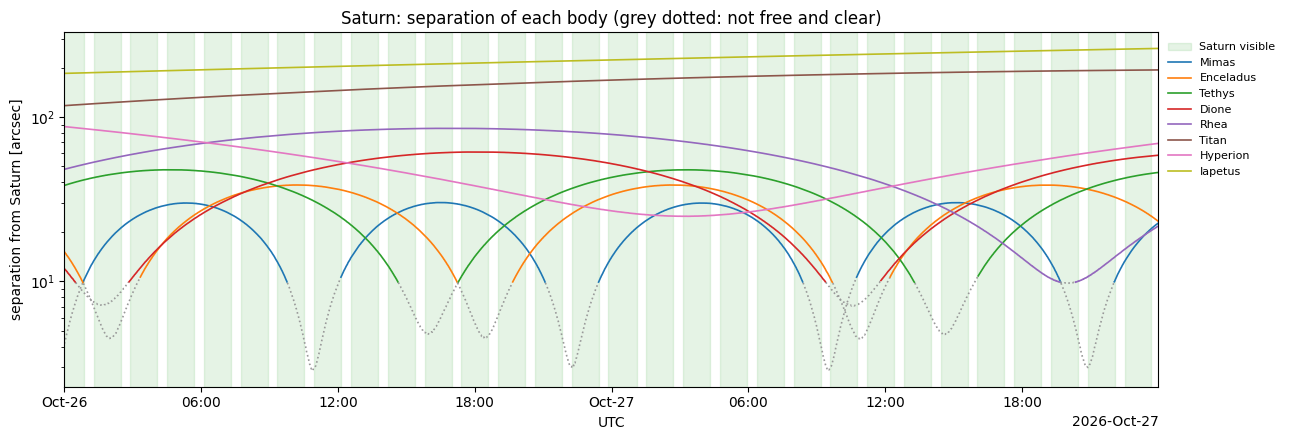

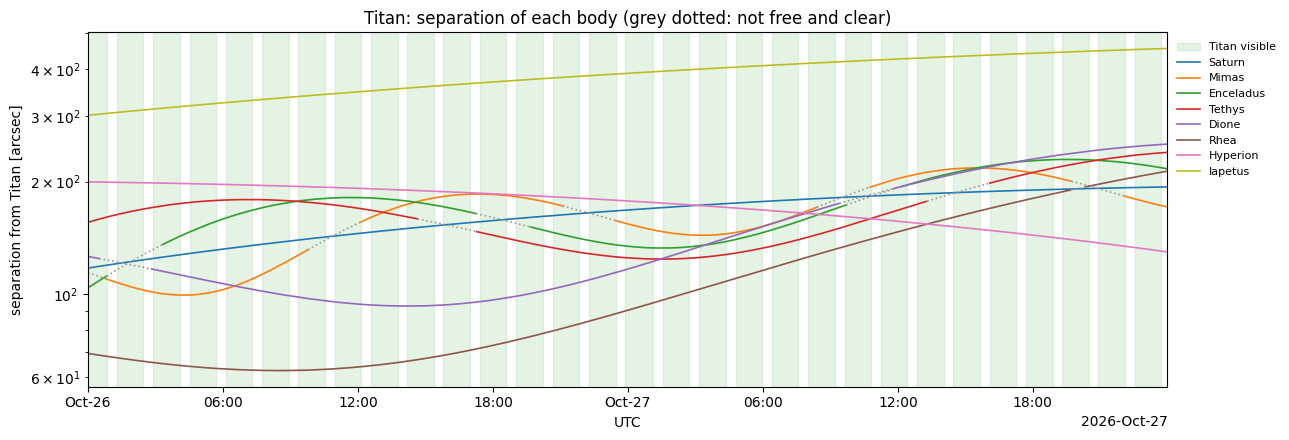

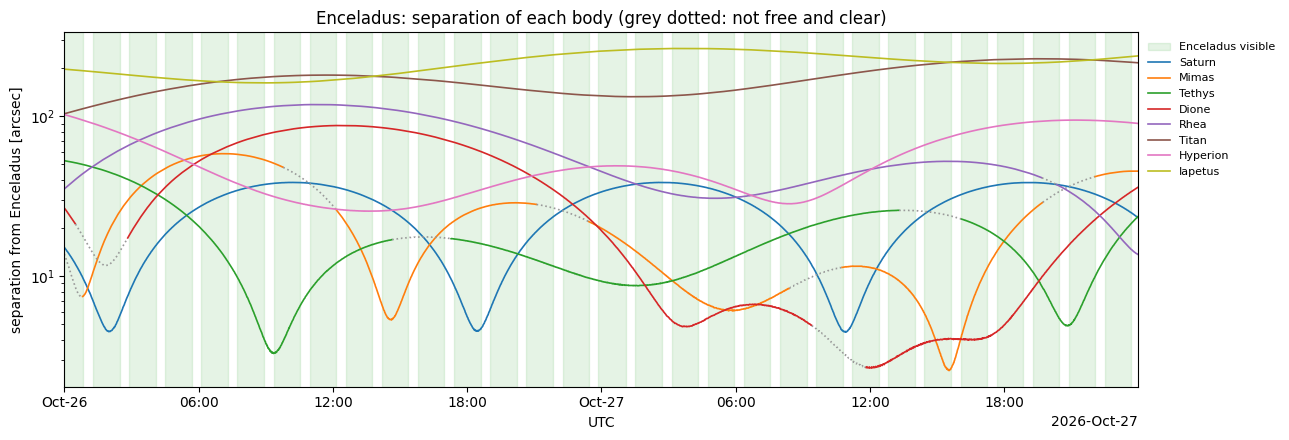

In [5]:
# Table rows every print_step_minutes (rounded to a multiple of the cadence)
print_step_minutes = 120.0
every = max(1, int(round(print_step_minutes / time_step_minutes)))
dates = times.to_datetime()

for target_id, label in targets:
    ephemeris = ephemerides[target_id]
    visible = results[label]["visible"]
    pointing = SkyCoord(*pandora_centric(ephemeris, visibility, times), unit="deg")
    geocentric = SkyCoord(ephemeris["ra"], ephemeris["dec"], unit="deg")
    others = [body_id for body_id in system_ids(target_id) if body_id != target_id]
    separation = {
        body_id: geocentric.separation(
            SkyCoord(ephemerides[body_id]["ra"], ephemerides[body_id]["dec"], unit="deg")
        ).arcsec
        for body_id in others
    }
    clear = {body_id: is_clear(body_id, ephemerides[body_id]) for body_id in others}
    rate = pointing[1:].separation(pointing[:-1]).arcsec / (time_step_minutes / 60.0)

    print(f"\n{label}: Pandora-centric pointing (astrometric ICRF) and "
          f"separations of the other bodies [arcsec]")
    print(f"  moves {np.median(rate):.1f}\"/h on the sky (up to {rate.max():.1f}\"/h); "
          f"Pandora's parallax shifts it up to "
          f"{pointing.separation(geocentric).arcsec.max():.1f}\" from the geocentric position")
    print(f"  {'UTC':<17}{'vis':>4}{'RA [deg]':>12}{'Dec [deg]':>11}   "
          f"{'RA (hms)':<14}{'Dec (dms)':<14}"
          + "".join(f"{labels[body_id]:>12}" for body_id in others))
    for index in range(0, len(times), every):
        ra_hms, dec_dms = pointing[index].to_string("hmsdms", precision=1).split()
        row = "".join(
            f"{separation[body_id][index]:>10.1f} "
            f"{'' if clear[body_id][index] else ephemerides[body_id]['code'][index]:1}"
            for body_id in others
        )
        print(f"  {times[index].iso[:16]:<17}{'yes' if visible[index] else '':>4}"
              f"{pointing[index].ra.deg:>12.5f}{pointing[index].dec.deg:>+11.5f}   "
              f"{ra_hms:<14}{dec_dms:<14}{row}")

    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.fill_between(dates, 0, 1, where=visible, transform=ax.get_xaxis_transform(),
                    color="tab:green", alpha=0.12, step="mid", label=f"{label} visible")
    # tab10 without its grey, which here means "not free and clear"
    colors = [c for i, c in enumerate(plt.cm.tab10.colors) if i != 7]
    for body_id, color in zip(others, colors):
        ax.plot(dates, np.where(clear[body_id], separation[body_id], np.nan),
                lw=1.2, color=color, label=labels[body_id])
        ax.plot(dates, np.where(clear[body_id], np.nan, separation[body_id]),
                lw=1.2, color="0.6", linestyle=":")
    ax.set_yscale("log")
    ax.set_ylabel(f"separation from {label} [arcsec]")
    ax.set_title(f"{label}: separation of each body (grey dotted: not free and clear)")
    format_date_axis(ax, times)
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
    plt.tight_layout()

## When is each target visible, and which bodies are clear?

One plot per target. The first row is the target itself; the rows below are the other bodies of its system. A blue box marks when that body is free and clear (not transiting, occulted or eclipsed; a planet always is), and the green line marks when it is **observable**: the target is visible *and* that body is clear. For a moon target, its own row therefore shows when it can actually be observed; for a planet target, the moon rows show when each moon is in view beside it.

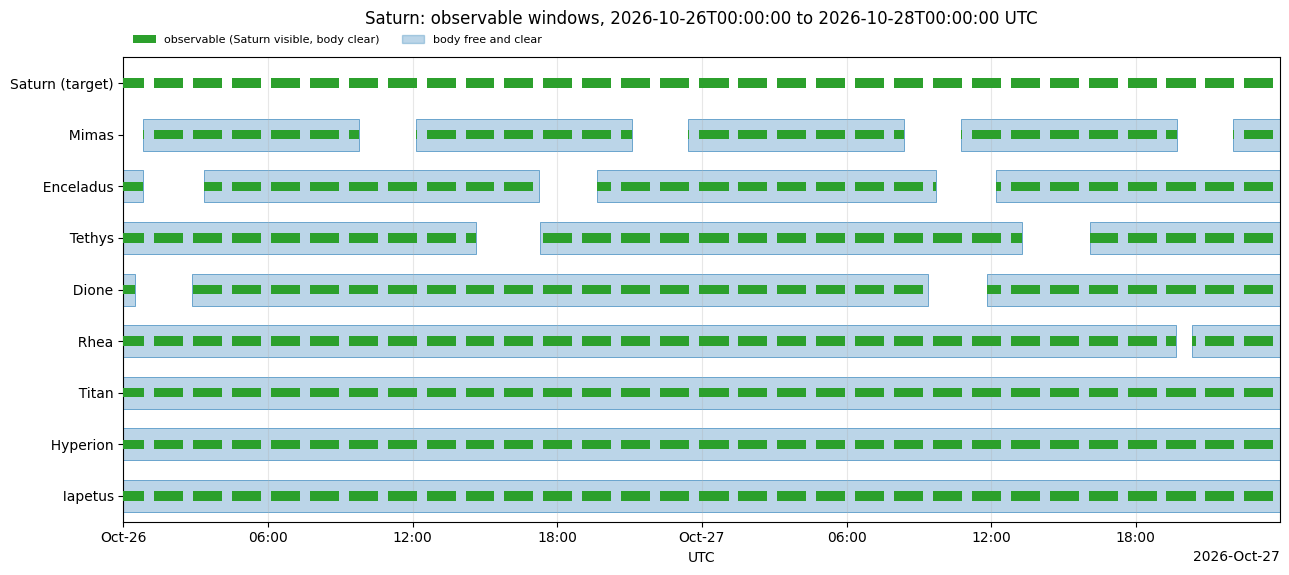

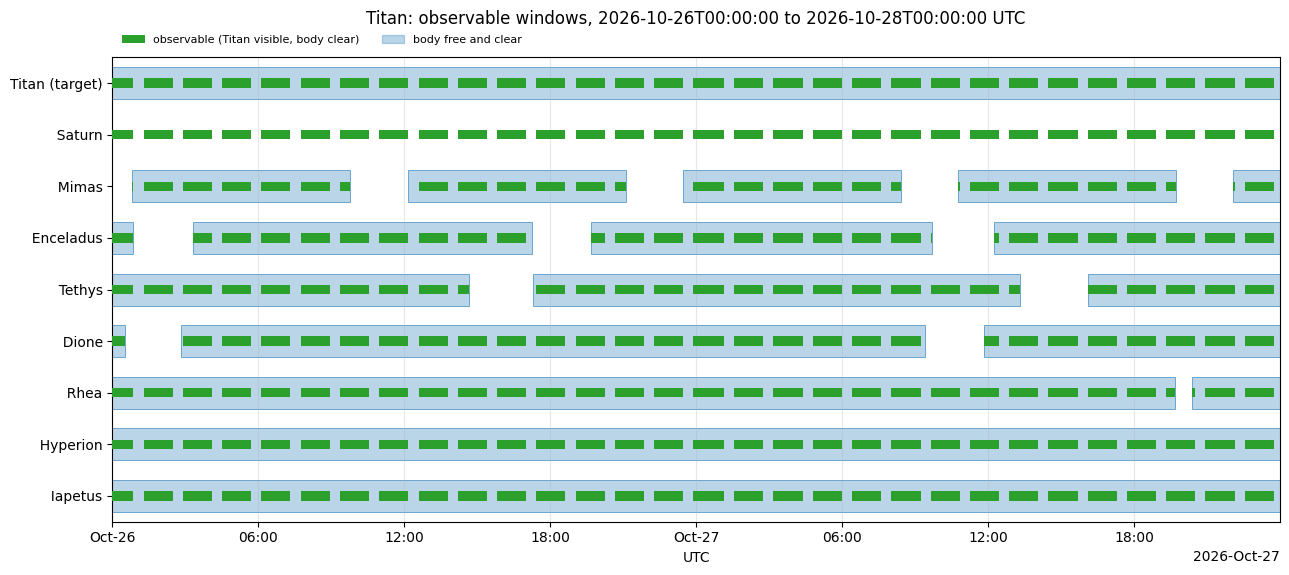

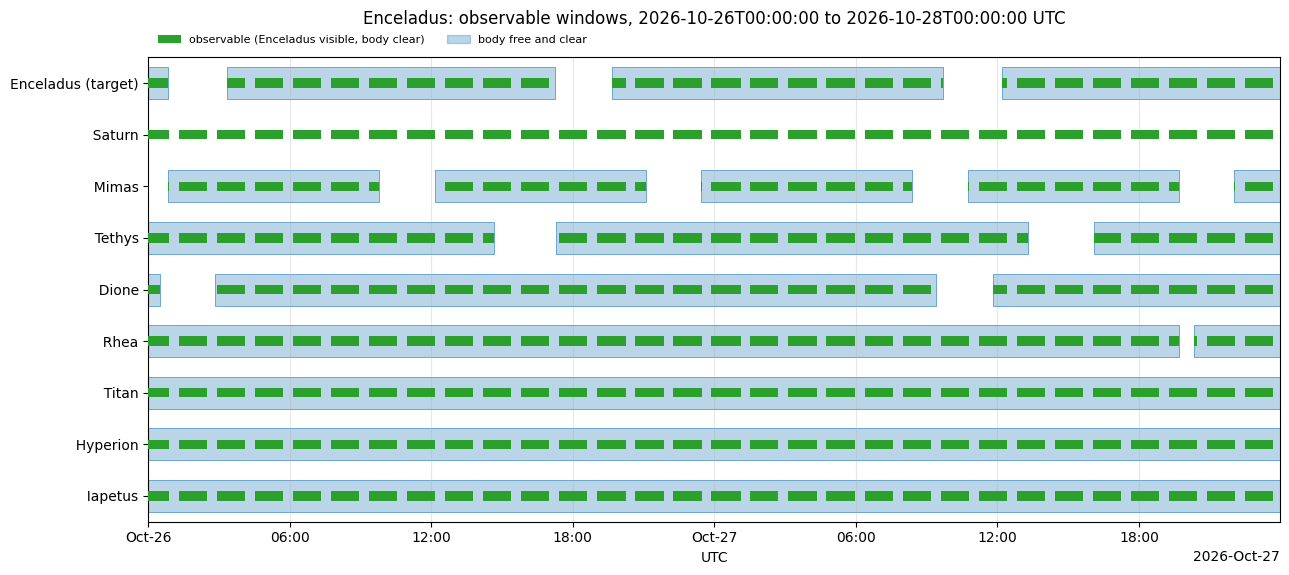

In [6]:
CLEAR_COLOR = "tab:blue"

for target_id, label in targets:
    result = results[label]
    bodies = [target_id] + [b for b in system_ids(target_id) if b != target_id]
    fig, ax = plt.subplots(figsize=(13, 0.45 * len(bodies) + 1.8))
    for row, body_id in enumerate(bodies):
        clear = is_clear(body_id, ephemerides[body_id])
        if body_id % 100 != 99:
            draw_event_box(
                ax, row, mask_segments(times, clear, time_step_minutes), CLEAR_COLOR
            )
        draw_row(
            ax, row,
            mask_segments(times, result["visible"] & clear, time_step_minutes),
            "tab:green",
        )
    label_rows(ax, [labels[target_id] + " (target)"]
               + [f"  {labels[body_id]}" for body_id in bodies[1:]])
    format_date_axis(ax, times)
    ax.set_title(f"{label}: observable windows, {start_utc} to {stop_utc} UTC", pad=24)
    handles = [
        Patch(facecolor="tab:green", label=f"observable ({label} visible, body clear)"),
        Patch(facecolor=CLEAR_COLOR, alpha=0.30, edgecolor=CLEAR_COLOR,
              label="body free and clear"),
    ]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, 1.005),
              ncols=len(handles), fontsize=8, frameon=False)
    plt.tight_layout()

## Which constraint is failing?

As in `target_visibility.ipynb`: for each target, a bar marks the time steps where that row fails, and the grey row at the bottom is the overall "not visible" result. **Red rows are binding**; **amber rows are per-tracker detail**, binding only when no other tracker covers them (`st_required`). These are the pointing constraints only: whether a moon is occulted or eclipsed is shown in Cell 6, not here.

Saturn: not visible at 738 of 2880 steps
    moon           fails at     0 steps
    sun            fails at     0 steps
    earthlimb      fails at   524 steps
    star tracker   fails at   738 steps (needs either tracker)
      ST1 sun      < 50 deg at     0 steps
      ST1 moon     < 20 deg at     0 steps
      ST1 limb     < 30 deg at  1535 steps
      ST2 sun      < 50 deg at     0 steps
      ST2 moon     < 20 deg at     0 steps
      ST2 limb     < 30 deg at  1546 steps
Titan: not visible at 737 of 2880 steps
    moon           fails at     0 steps
    sun            fails at     0 steps
    earthlimb      fails at   527 steps
    star tracker   fails at   737 steps (needs either tracker)
      ST1 sun      < 50 deg at     0 steps
      ST1 moon     < 20 deg at     0 steps
      ST1 limb     < 30 deg at  1533 steps
      ST2 sun      < 50 deg at     0 steps
      ST2 moon     < 20 deg at     0 steps
      ST2 limb     < 30 deg at  1545 steps


Enceladus: not visible at 738 of 2880 steps
    moon           fails at     0 steps
    sun            fails at     0 steps
    earthlimb      fails at   524 steps
    star tracker   fails at   738 steps (needs either tracker)
      ST1 sun      < 50 deg at     0 steps
      ST1 moon     < 20 deg at     0 steps
      ST1 limb     < 30 deg at  1535 steps
      ST2 sun      < 50 deg at     0 steps
      ST2 moon     < 20 deg at     0 steps
      ST2 limb     < 30 deg at  1546 steps


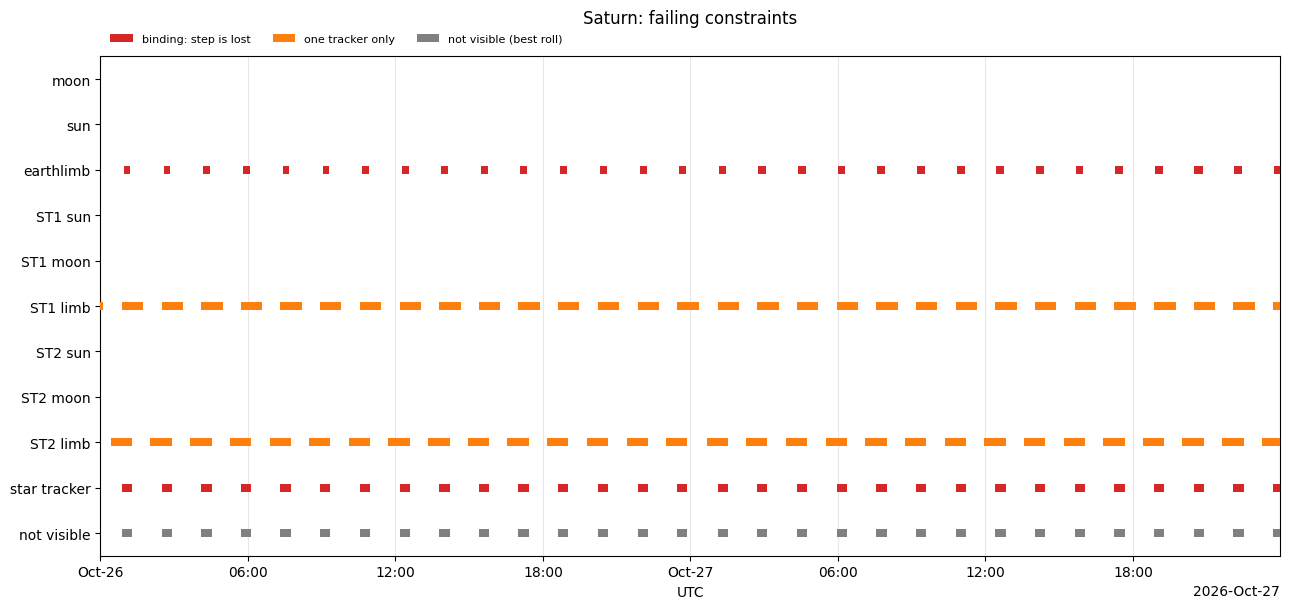

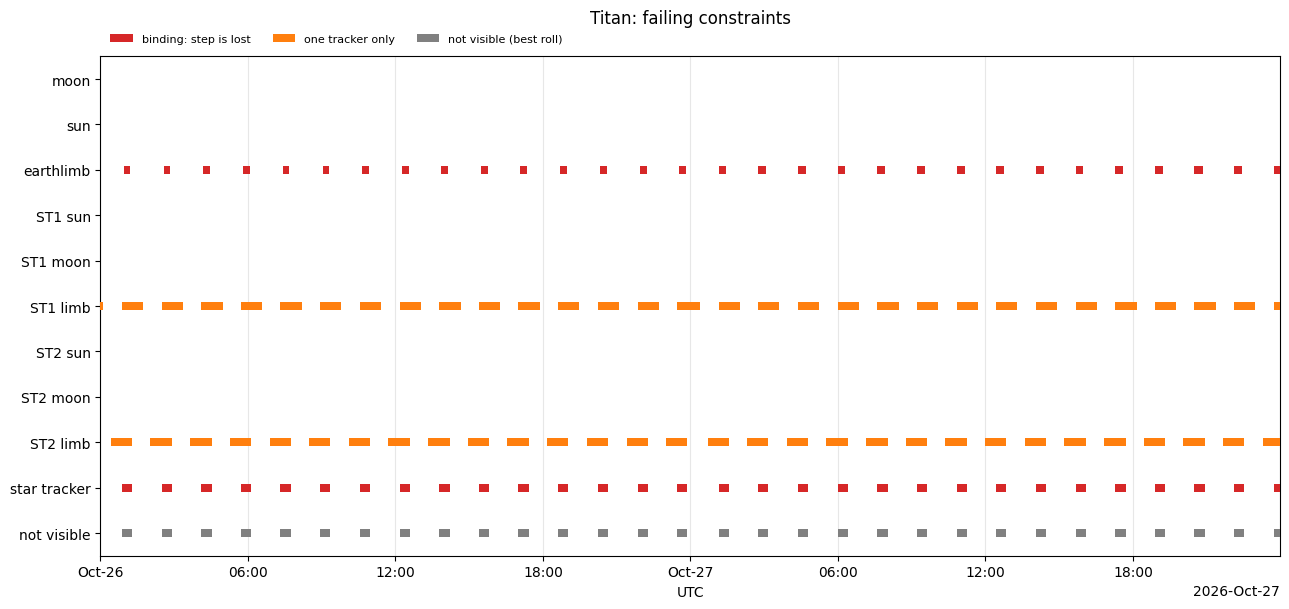

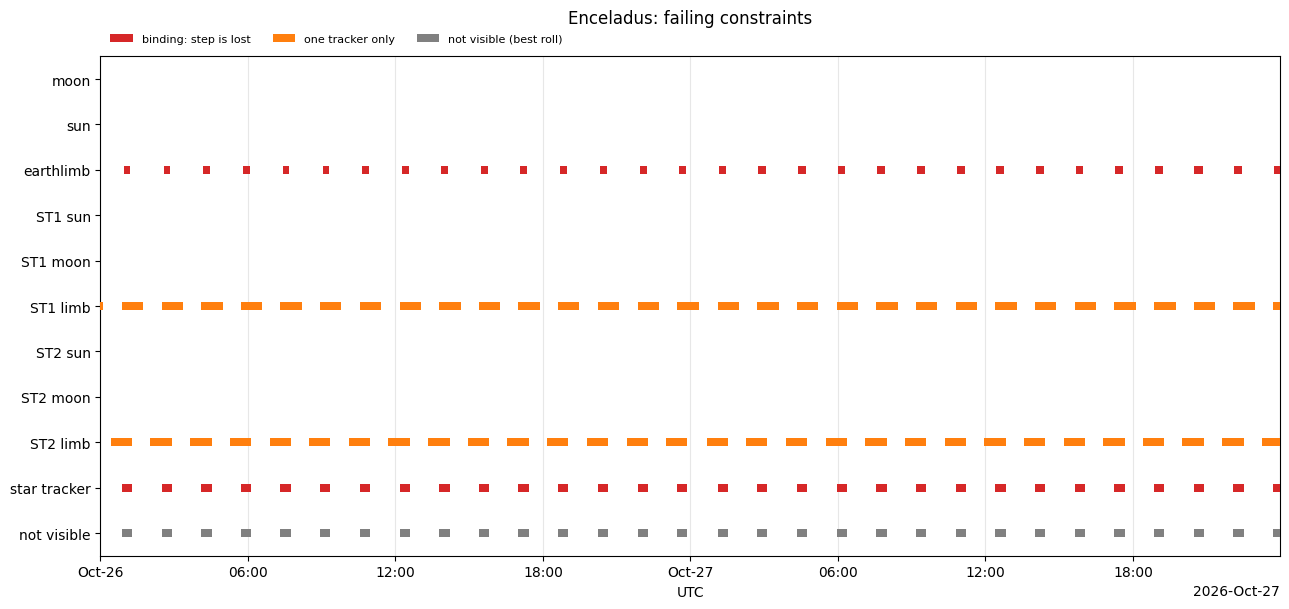

In [7]:
BINDING_COLOR = "tab:red"
TRACKER_COLOR = "tab:orange"

for label, result in results.items():
    not_visible = ~result["visible"]
    binding = {
        name.replace("_", " "): ~passed for name, passed in result["constraints"].items()
    }
    detail = {
        name: ~passed
        for name, passed in result["tracker_checks"].items()
        if name not in ("ST1", "ST2", "combined")
    }
    explained = np.zeros_like(not_visible)
    for fail_mask in binding.values():
        explained |= fail_mask
    unexplained = int(np.sum(not_visible & ~explained))

    boresight = [name for name in binding if name != "star tracker"]
    st_rows = ["star tracker"] if "star tracker" in binding else []
    rows = boresight + list(detail) + st_rows + ["not visible"]

    fig, ax = plt.subplots(figsize=(13, 0.4 * len(rows) + 1.8))
    for row, name in enumerate(rows):
        if name == "not visible":
            mask, color = not_visible, "0.5"
        elif name in detail:
            mask, color = detail[name], TRACKER_COLOR
        else:
            mask, color = binding[name], BINDING_COLOR
        draw_row(ax, row, mask_segments(times, mask, time_step_minutes), color)
    label_rows(ax, rows)
    format_date_axis(ax, times)
    ax.set_title(f"{label}: failing constraints", pad=24 if detail else 6)
    if detail:
        handles = [
            Patch(facecolor=BINDING_COLOR, label="binding: step is lost"),
            Patch(facecolor=TRACKER_COLOR, label="one tracker only"),
            Patch(facecolor="0.5", label="not visible (best roll)"),
        ]
        ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, 1.005),
                  ncols=len(handles), fontsize=8, frameon=False)
    plt.tight_layout()

    print(f"{label}: not visible at {int(not_visible.sum())} of {len(times)} steps")
    for name in boresight:
        print(f"    {name:<14} fails at {int(binding[name].sum()):>5} steps")
    if detail:
        need = "both trackers" if visibility.st_required == 2 else "either tracker"
        print(f"    {'star tracker':<14} fails at "
              f"{int(binding['star tracker'].sum()):>5} steps (needs {need})")
        for name, mask in detail.items():
            print(f"      {name:<12} < {result['limits'][name].value:.0f} deg at "
                  f"{int(mask.sum()):>5} steps")
    if unexplained:
        print(f"    WARNING: {unexplained} not-visible steps are not explained "
              f"by any row above; the rows and the result have diverged")

## The NIRDA subarray each day

For each target and each day it is visible, the simulated `nirda_roi_x` x `nirda_roi_y` subarray at the roll held that day, at the middle visible time step (`trace.plot_trace`). The target sits at the pivot; the other bodies of its system and the Gaia field stars (J < 14) are drawn as traces, labeled by name or J. The dashed box is the target's extraction aperture, and each title gives the time, the roll and the trace contamination of that aperture (worst spectral channel, within ±1° of roll error).

Approximations, all in `solar_system_helpers.py`:
- A body wider than two pixels (here only the planet) is a uniform oblate disk, plus Saturn's A and B rings at the Horizons ring opening angle with the disk's surface brightness. Ring shadows, the disk hidden behind the rings and limb darkening are ignored.
- Brightness ratios use J = V - 1.15 (sunlight's color) from Horizons' visual magnitudes. Methane bands make Saturn and Titan fainter in the near infrared than that.
- A moon occulted by its planet or fully eclipsed is left out of the panel; a partially eclipsed or transiting moon is drawn at its Horizons magnitude.

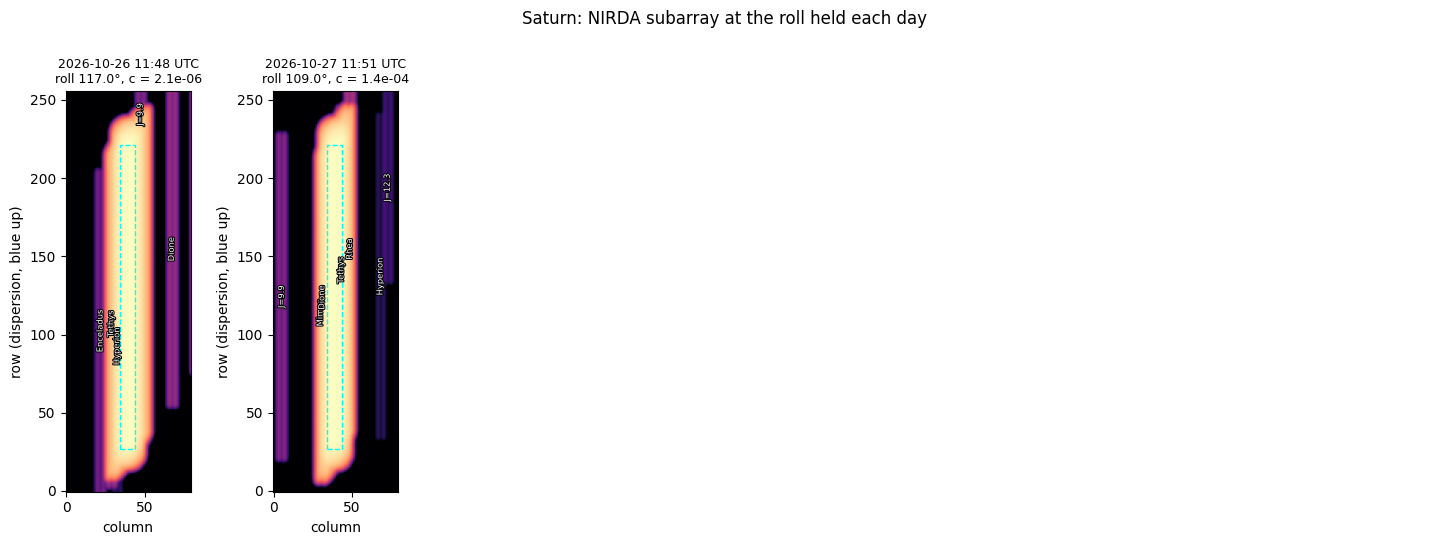

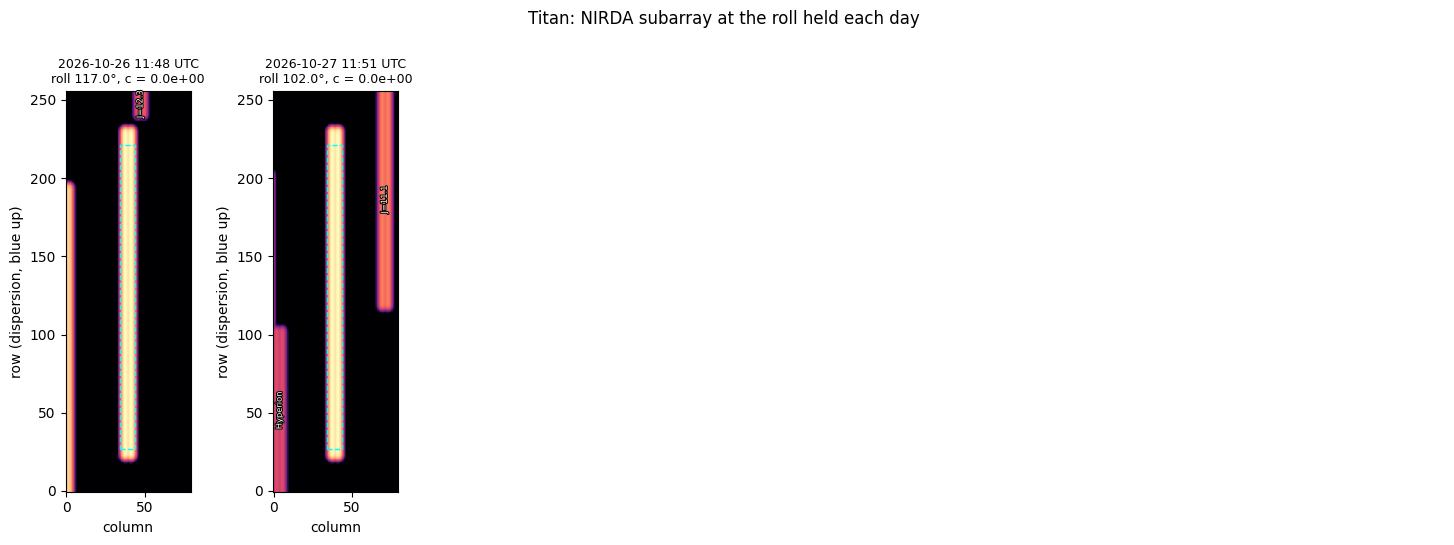

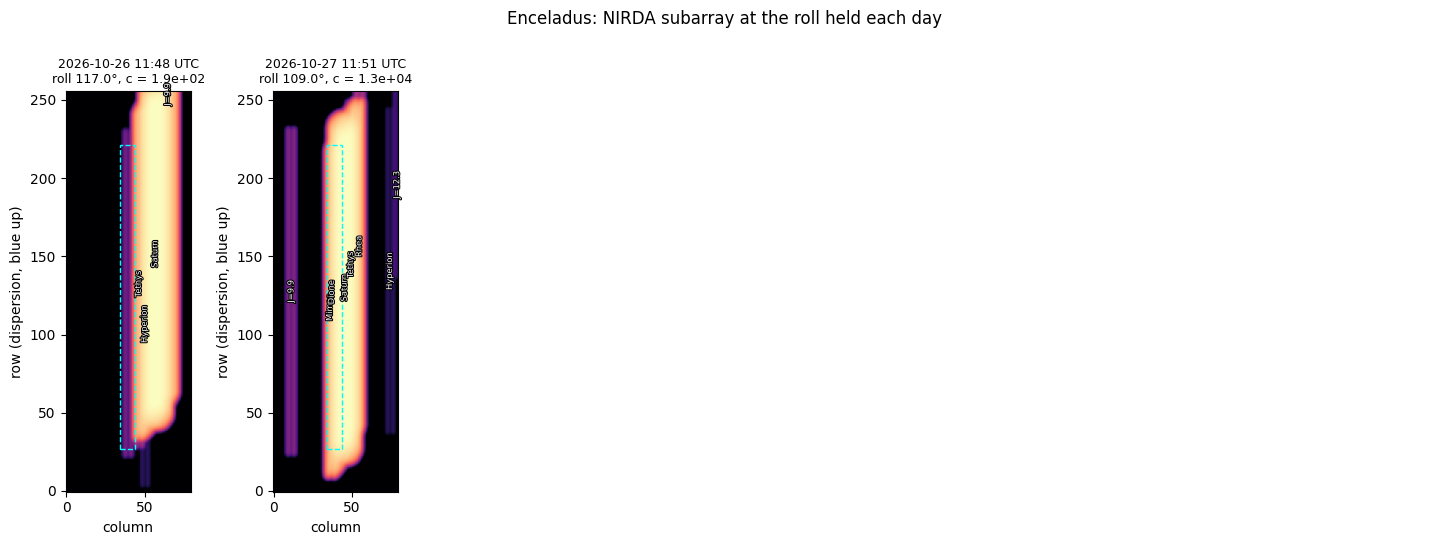

In [8]:
n_columns = 7
for target_id, label in targets:
    result = results[label]
    # Middle visible step of each day
    panels = []
    for day in days:
        indices = np.flatnonzero((day_of == day) & result["visible"])
        if indices.size:
            panels.append(indices[indices.size // 2])
    if not panels:
        print(f"{label}: not visible on any day, so no subarray panels")
        continue

    n_rows = int(np.ceil(len(panels) / n_columns))
    fig, axes = plt.subplots(
        n_rows, n_columns, figsize=(2.1 * n_columns, 5.4 * n_rows), squeeze=False
    )
    for ax, index in zip(axes.flat, panels):
        field = system_field(
            target_id, ephemerides, index, times[index], labels,
            include_stars=include_field_stars,
        )
        trace.plot_trace(
            field,
            result["roll_deg"][index] * u.deg,
            visibility.nirda_roi_x,
            visibility.nirda_roi_y,
            ax=ax,
            title=f"{times[index].iso[:16]} UTC",
        )
    for ax in axes.flat[len(panels):]:
        ax.set_axis_off()
    fig.suptitle(f"{label}: NIRDA subarray at the roll held each day", y=1.0)
    plt.tight_layout()